# 表格拟合与残差分析 · Agent Skill

用有出处的咖啡因HPLC校准数据，检查参数、实际调用数值工具并解释残差。此Notebook包含功能说明、环境、参数、运行和下载。

在线预览图表来自已验收来源样板；你的本次结果以实际运行回执为准。仓库保持私有，请下载本Notebook后在Colab上传；通过已授权的GitHub账号阅读或下载。

本地读取你设置的.env，Colab读取DEEPSEEK_API_KEY Secret。准备代码默认折叠；不要把密钥写入代码。新RHF未验收。


In [ ]:
# @title 环境与样本准备（内置资源默认折叠）
from pathlib import Path
import base64, hashlib, io, json, os, subprocess, sys, uuid, zipfile
from IPython.display import display, Markdown, Image, HTML
RESOURCE_SHA256 = '2fe461483306c6d5d04bf0447e061319cb6f700e3f879ce1d5788e3acdcee081'
RESOURCE_B64 = '...'
raw = base64.b64decode(RESOURCE_B64)
if hashlib.sha256(raw).hexdigest() != RESOURCE_SHA256: raise ValueError("Resource checksum mismatch")
base = Path('/content') if Path('/content').is_dir() else Path.cwd()
workspace = base / ('table-skill-' + uuid.uuid4().hex)
workspace.mkdir()
with zipfile.ZipFile(io.BytesIO(raw)) as archive:
    if archive.testzip() is not None: raise ValueError('Corrupt resource ZIP')
    for name in archive.namelist():
        if Path(name).name != name: raise ValueError('Invalid bundled path')
    archive.extractall(workspace)
for item in json.loads((workspace/'resource-manifest.json').read_text('utf-8')):
    if hashlib.sha256((workspace/item['file']).read_bytes()).hexdigest()!=item['sha256']: raise ValueError('Resource hash mismatch')
venv = workspace / '.venv'
subprocess.run([sys.executable, '-m', 'venv', '--without-pip', str(venv)], check=True, capture_output=True)
python = venv / ('Scripts/python.exe' if os.name == 'nt' else 'bin/python')
install = subprocess.run([sys.executable, '-m', 'pip', '--python', str(python), 'install', '--disable-pip-version-check', '-r', str(workspace/'requirements-colab.txt')],capture_output=True,text=True)
(workspace/'installation.log').write_text(install.stdout+'\n'+install.stderr, encoding='utf-8')
if install.returncode: raise RuntimeError('Dependency installation failed; inspect installation.log; no Agent call performed')
check=subprocess.run([sys.executable, '-m', 'pip', '--python', str(python), 'check'],capture_output=True,text=True)
if check.returncode: raise RuntimeError('Private environment pip check failed')
print('独立环境与资源校验通过；提供者DeepSeek；没有调用OpenAI服务；未执行新RHF。')
guide = (workspace/'README.md').read_text('utf-8')
guide = guide.replace('(example-calibration-and-residuals.png)', '(data:image/png;base64,'+base64.b64encode((workspace/'example-calibration-and-residuals.png').read_bytes()).decode('ascii')+')')
display(Markdown(guide))


## 任务模板与参数

保留原始数据。默认使用4个标准；改为false仅做明确的3点敏感性练习，不把最高点认定为错误。未知样本峰面积来自教材；修改它属于你定义的假设输入。拟合截距固定为true。

In [ ]:
INCLUDE_HIGHEST_STANDARD = True # @param {type:"boolean"}
UNKNOWN_PEAK_AREA = 424195.0 # @param {type:"number"}
parameters = {"include_highest_standard": INCLUDE_HIGHEST_STANDARD, "unknown_peak_area": UNKNOWN_PEAK_AREA, "fit_intercept": True}
print(parameters)
display(Markdown((workspace/'task-template.txt').read_text('utf-8')))


# 凭据配置：本地.env / Colab Secret

程序只保留变量名 `DEEPSEEK_API_KEY`，不填写密钥值。本地和云端的读取位置不同。

## 本地 Jupyter

将Notebook下载到本机并打开。凭据单元中的 `ENV_FILE` 默认指向当前工作目录的 `.env`；它是本地路径设置，不是密钥。程序只读取此文件中唯一的 `DEEPSEEK_API_KEY` 项，不读取其它提供者配置，也不修改文件；不从操作系统环境变量静默覆盖该值。可保留原文件中的引号或行尾注释。

文件不存在会提示检查路径；变量缺失、重复、空值或格式错误会分别停止。无需把密钥写到Notebook、聊天或参数JSON。不上传整个.env。换电脑时仅修改本机配置路径。

## Colab

Colab运行在Google云端，无法读取本机D盘。打开左侧钥匙图标 **Secret**，点击 **添加新密钥**：

| 位置 | 填写内容 |
| --- | --- |
| 名称 | `DEEPSEEK_API_KEY`（固定变量名） |
| 值 | 你自己的DeepSeek密钥；仅在Secret面板填写 |
| 笔记本访问权限 | 为当前Notebook开启；新副本需单独核对 |

不要把值替换到 `userdata.get('DEEPSEEK_API_KEY')` 中，也不要修改此名称。若Notebook报错，先读提示：Secret不存在→检查名称与账号；未授权→开启当前Notebook访问；其它读取失败→确认登录与Secret保存状态。凭据单元只显示读取成功或安全提示，不显示值。配置完成后再运行凭据、调用、结果和下载单元。

## 调用失败与重跑

HTTP 401：密钥无效或已撤销；402：检查DeepSeek账户可用额度；429：速率限制，稍后手动重试；5xx：提供者服务异常；网络超时/连接失败：检查网络后手动重试。不自动循环请求，不把配置成功当模型调用成功。执行失败时显示安全的失败类型与HTTP状态，不回显认证头、响应正文或密钥。

若出现“保存失败：笔记本已在此会话外部更改”，这是版本冲突，与密钥是否有效无关。使用“文件→在云端硬盘中保存一份副本”保留修改，不强制覆盖其它会话。云端调用与下载仍需单独验收。

安全边界：不在代码、Notebook输出、日志或结果包保存密钥；子进程仅通过内存环境接收所选密钥。已误写入代码的旧密钥应由用户在提供者后台撤销并更换；不要把旧值放进报告。


In [ ]:
# 此处只设置本地文件路径，不能填写密钥值。
ENV_FILE = str(__import__('pathlib').Path.cwd() / '.env')
globals().pop('deepseek_key', None)  # 配置失败时不能继续使用上次的凭据
import importlib.util
config_spec = importlib.util.spec_from_file_location('sample_credentials', workspace/'credential_config.py')
config_module = importlib.util.module_from_spec(config_spec)
config_spec.loader.exec_module(config_module)
try:
    deepseek_key = config_module.load_credential(ENV_FILE)
except config_module.CredentialConfigError as error:
    raise RuntimeError(str(error)) from None
print('所选凭据已读取到内存；未显示或写入文件。')


## 实际调用Skill

将准确Skill原文作为Agent指令，DeepSeek返回工具调用，白名单程序计算并独立复核后返回结果供模型解释。不执行模型生成的代码；每次输出到新目录。凭据只通过子进程环境传入，不进入文件或命令行参数。

In [ ]:
parameter_file = workspace / ('parameters-' + uuid.uuid4().hex + '.json')
parameter_file.write_text(json.dumps(parameters,ensure_ascii=False,allow_nan=False),encoding='utf-8')
run_output = workspace / ('run-' + uuid.uuid4().hex)
child_env = dict(os.environ)
child_env['MPLBACKEND'] = 'Agg'  # 仅为私有计算子进程指定离线绘图后端
child_env['DEEPSEEK_API_KEY'] = deepseek_key
try:
    execution = subprocess.run([str(python), '-B', str(workspace/'cloud-run.py'), str(parameter_file), str(run_output), ('COLAB' if 'google.colab' in __import__('sys').modules else 'LOCAL_WINDOWS')],env=child_env,capture_output=True,text=True,timeout=260)
finally:
    child_env.pop('DEEPSEEK_API_KEY',None)
    del deepseek_key
if execution.returncode:
    safe_hints = ['凭据无效或已撤销', '请检查DeepSeek账户额度', '请求频率受限']
    hint = next((h for h in safe_hints if h in execution.stderr), '检查网络或新输出目录failure.json的安全失败类型')
    raise RuntimeError('本次调用失败：'+hint+'；未验收，不自动重试。')
receipt = json.loads((run_output/'run-receipt.json').read_text('utf-8'))
if receipt['status'] != 'PASS_REAL_MODEL_AND_TOOL_CALL': raise RuntimeError('没有合格的实际调用回执')
print(json.dumps(receipt,ensure_ascii=False,indent=2))


## 查看程序结果、图表与Agent解释

以numerical-result.json为数值依据；Agent解释单独显示，未经教师或专家独立评定。先解释系数单位、残差和4点/3点的局限，再做参数练习。

来源样板保存输出（本次新运行会替换以下输出）：
{
  "execution_status": "SUCCEEDED",
  "numerical_checks": "PASS",
  "analysis_scope": "descriptive external-standard OLS calibration only",
  "n": 4,
  "df_residual": 2,
  "intercept": 16714.88489208635,
  "intercept_unit": "peak area arbitrary units",
  "slope": 4317.536115107914,
  "slope_unit": "peak area arbitrary units / (mg/L)",
  "rss": 77729900.3597121,
  "rss_unit": "(peak area arbitrary units)^2",
  "r_squared": 0.9998080456519541,
  "residual_convention": "observed minus fitted",
  "unknown_peak_area": 424195.0,
  "sample_concentration_mg_L": 94.37792857876974,
  "inside_calibration_range": true,
  "used_ids": [
    "standard-50",
    "standard-100",
    "standard-125",
    "standard-250"
  ],
  "independent_decimal_oracle": {
    "intercept": "16714.8848920863309352517985611510791366906475",
    "slope": "4317.53611510791366906474820143884892086330935",
    "concentration_mg_L": "94.3779285787697459742227081552908073469560776"
  },
  "checks": {
   

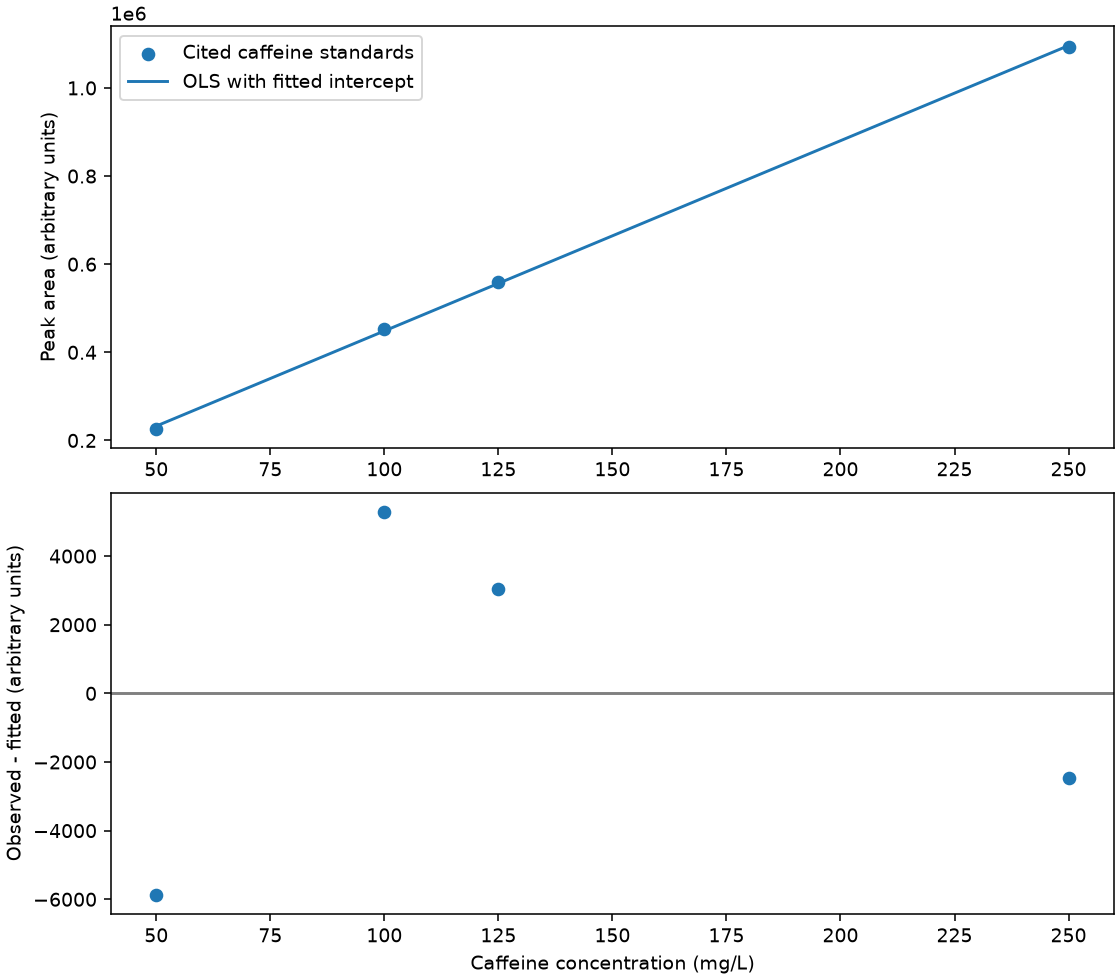

保存输出来自有来源教材数据的真实Colab运行。正的拟合截距不确立基线成因；4点且无重复不能证明模型充分或方差恒定。模型生成的解释应另行审阅。

In [ ]:
numerical = json.loads((run_output/'numerical-result.json').read_text('utf-8'))
print(json.dumps(numerical,ensure_ascii=False,indent=2))
display(Image(filename=str(run_output/'calibration-and-residuals.png')))
display(Markdown('### Agent生成的解释（单独审阅）\n\n'+(run_output/'agent-explanation.md').read_text('utf-8')))


## 下载结果并保存Notebook

结果ZIP保存Skill、参数、真实调用轨迹、数值结果、图表、来源和清单。另用“文件→下载→下载.ipynb”保存本适配Notebook。修改参数后需要重跑参数、凭据、调用、显示和下载单元；不用重复安装。

In [ ]:
archive = run_output/'skill-results.zip'
with zipfile.ZipFile(archive) as z:
    if z.testzip() is not None: raise ValueError('ZIP integrity failure')
    for item in json.loads(z.read('export-manifest.json')):
        if hashlib.sha256(z.read(item['file'])).hexdigest()!=item['sha256']: raise ValueError('Result checksum mismatch')
encoded = base64.b64encode(archive.read_bytes()).decode('ascii')
display(HTML('<a download="table-fitting-skill-results.zip" href="data:application/zip;base64,'+encoded+'">下载本次Skill结果ZIP</a>'))
print('结果ZIP SHA-256: '+hashlib.sha256(archive.read_bytes()).hexdigest())
